In [1]:
import os

for folder, subfolders, files in os.walk("/kaggle/input"):
    print(folder, "->", len(files), "files")

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input -> 0 files
/kaggle/input/datasets -> 0 files
/kaggle/input/datasets/patrickfleith -> 0 files
/kaggle/input/datasets/patrickfleith/nasa-anomaly-detection-dataset-smap-msl -> 1 files
/kaggle/input/datasets/patrickfleith/nasa-anomaly-detection-dataset-smap-msl/data -> 0 files
/kaggle/input/datasets/patrickfleith/nasa-anomaly-detection-dataset-smap-msl/data/data -> 0 files
/kaggle/input/datasets/patrickfleith/nasa-anomaly-detection-dataset-smap-msl/data/data/2018-05-19_15.00.10 -> 1 files
/kaggle/input/datasets/patrickfleith/nasa-anomaly-detection-dataset-smap-msl/data/data/2018-05-19_15.00.10/models -> 82 files
/kaggle/input/datasets/patrickfleith/nasa-anomaly-detection-dataset-smap-msl/data/data/2018-05-19_15.00.10/smoothed_errors -> 82 files
/kaggle/input/datasets/patrickfleith/nasa-anomaly-detection-dataset-smap-msl/data/data/2018-05-19_15.00.10/y_hat -> 82 files
/kaggle/input/datasets/patrickfleith/nasa-anomaly-detection-dataset-smap-msl/data/data/test -> 82 files
/kaggl

train shape: (2872, 25)
test shape: (8505, 25)


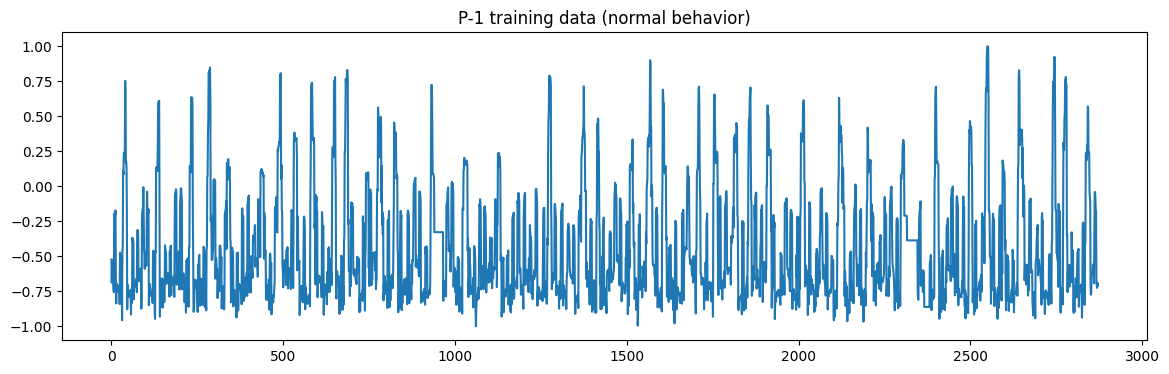

In [2]:
import numpy as np
import matplotlib.pyplot as plt

BASE = "/kaggle/input/datasets/patrickfleith/nasa-anomaly-detection-dataset-smap-msl/"

train = np.load(BASE + "data/data/train/P-1.npy")
test = np.load(BASE + "data/data/test/P-1.npy")

print("train shape:", train.shape)
print("test shape:", test.shape)

plt.figure(figsize=(14, 4))
plt.plot(train[:, 0])
plt.title("P-1 training data (normal behavior)")
plt.show()

In [3]:
import pandas as pd
import ast

labels = pd.read_csv(BASE + "labeled_anomalies.csv")
row = labels[labels.chan_id == "P-1"].iloc[0]

print(row)

true_seqs = ast.literal_eval(row.anomaly_sequences)
print("Anomaly location(s):", true_seqs)

chan_id                                                     P-1
spacecraft                                                 SMAP
anomaly_sequences    [[2149, 2349], [4536, 4844], [3539, 3779]]
class                      [contextual, contextual, contextual]
num_values                                                 8505
Name: 0, dtype: object
Anomaly location(s): [[2149, 2349], [4536, 4844], [3539, 3779]]


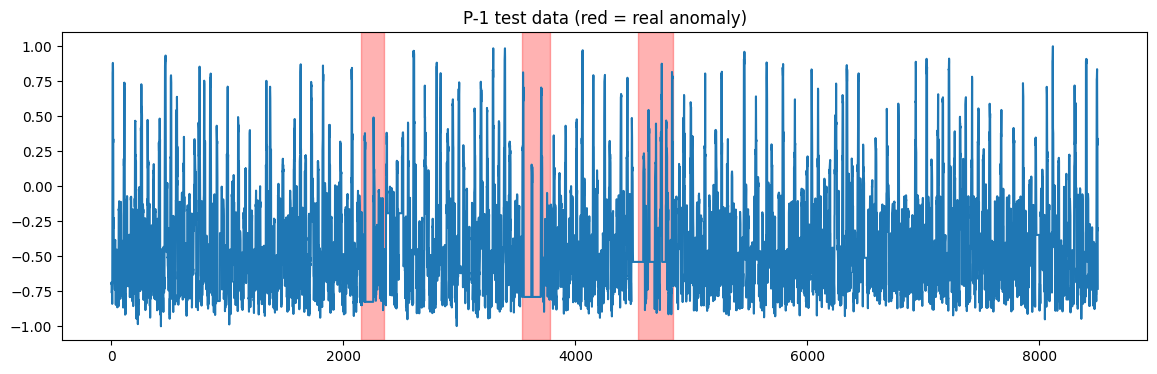

In [4]:
plt.figure(figsize=(14, 4))
plt.plot(test[:, 0])

for start, end in true_seqs:
    plt.axvspan(start, end, color="red", alpha=0.3)

plt.title("P-1 test data (red = real anomaly)")
plt.show()

In [5]:
signal = test[:, 0]

mean = train[:, 0].mean()
std = train[:, 0].std()

z = np.abs(signal - mean) / std   # how many "wiggles" away from normal
flags = z > 3                     # True where something looks off

print("Steps flagged:", flags.sum(), "out of", len(flags))

Steps flagged: 124 out of 8505


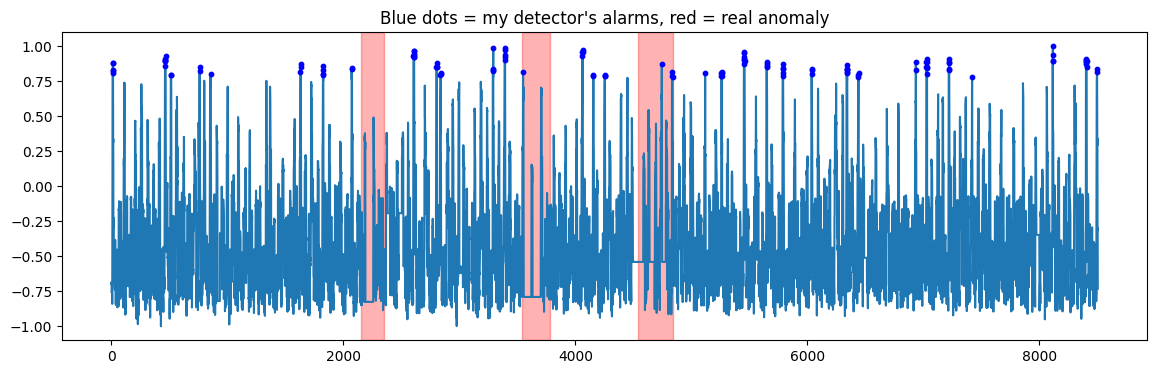

In [6]:
plt.figure(figsize=(14, 4))
plt.plot(signal)

for start, end in true_seqs:
    plt.axvspan(start, end, color="red", alpha=0.3)

bad = np.flatnonzero(flags)
plt.scatter(bad, signal[bad], color="blue", s=10, zorder=3)
plt.title("Blue dots = my detector's alarms, red = real anomaly")
plt.show()

In [7]:
def to_sequences(flags):
    idx = np.flatnonzero(flags)
    if len(idx) == 0:
        return []
    splits = np.split(idx, np.flatnonzero(np.diff(idx) > 1) + 1)
    return [[s[0], s[-1]] for s in splits]

def score(pred_seqs, true_seqs):
    hit = lambda a, b: a[0] <= b[1] and b[0] <= a[1]
    found = sum(any(hit(p, t) for p in pred_seqs) for t in true_seqs)
    false_alarms = sum(not any(hit(p, t) for t in true_seqs) for p in pred_seqs)
    missed = len(true_seqs) - found
    return found, false_alarms, missed

pred_seqs = to_sequences(flags)
found, false_alarms, missed = score(pred_seqs, true_seqs)

print("Real anomalies:", len(true_seqs))
print("Found:", found)
print("False alarms:", false_alarms)
print("Missed:", missed)

Real anomalies: 3
Found: 2
False alarms: 37
Missed: 1


In [8]:
L = 250  # how many past steps the model looks at

def make_windows(x):
    X = np.stack([x[i:i + L] for i in range(len(x) - L)])
    y = x[L:, 0]
    return X.astype("float32"), y.astype("float32")

X_train, y_train = make_windows(train)
X_test, y_test = make_windows(test)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (2622, 250, 25)
y_train: (2622,)
X_test: (8255, 250, 25)
y_test: (8255,)


In [9]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"

# hold back the last 20% of training windows for validation
split = int(len(X_train) * 0.8)
Xtr, ytr = X_train[:split], y_train[:split]
Xval, yval = X_train[split:], y_train[split:]

loader = DataLoader(
    TensorDataset(torch.tensor(Xtr), torch.tensor(ytr)),
    batch_size=64, shuffle=True
)
Xval_t = torch.tensor(Xval).to(device)
yval_t = torch.tensor(yval).to(device)

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=25, hidden_size=80,
                            num_layers=2, dropout=0.3, batch_first=True)
        self.out = nn.Linear(80, 1)

    def forward(self, x):
        o, _ = self.lstm(x)              # read all 250 steps
        return self.out(o[:, -1, :]).squeeze(1)   # guess from the last step

model = Net().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

best_val, best_state, patience, bad_epochs = float("inf"), None, 5, 0

for epoch in range(30):
    model.train()
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(Xval_t), yval_t).item()
    print(f"epoch {epoch+1}  validation loss: {val_loss:.5f}")

    if val_loss < best_val:
        best_val, bad_epochs = val_loss, 0
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print("No improvement for 5 epochs, stopping early.")
            break

model.load_state_dict(best_state)
print("Done. Best validation loss:", round(best_val, 5))

epoch 1  validation loss: 0.12613
epoch 2  validation loss: 0.08340
epoch 3  validation loss: 0.06512
epoch 4  validation loss: 0.05269
epoch 5  validation loss: 0.05189
epoch 6  validation loss: 0.04696
epoch 7  validation loss: 0.04294
epoch 8  validation loss: 0.04061
epoch 9  validation loss: 0.04162
epoch 10  validation loss: 0.03565
epoch 11  validation loss: 0.03566
epoch 12  validation loss: 0.03341
epoch 13  validation loss: 0.03494
epoch 14  validation loss: 0.03253
epoch 15  validation loss: 0.03164
epoch 16  validation loss: 0.03252
epoch 17  validation loss: 0.03636
epoch 18  validation loss: 0.03091
epoch 19  validation loss: 0.03040
epoch 20  validation loss: 0.03000
epoch 21  validation loss: 0.02973
epoch 22  validation loss: 0.03023
epoch 23  validation loss: 0.02891
epoch 24  validation loss: 0.02872
epoch 25  validation loss: 0.02873
epoch 26  validation loss: 0.02827
epoch 27  validation loss: 0.02777
epoch 28  validation loss: 0.02747
epoch 29  validation loss: 0.

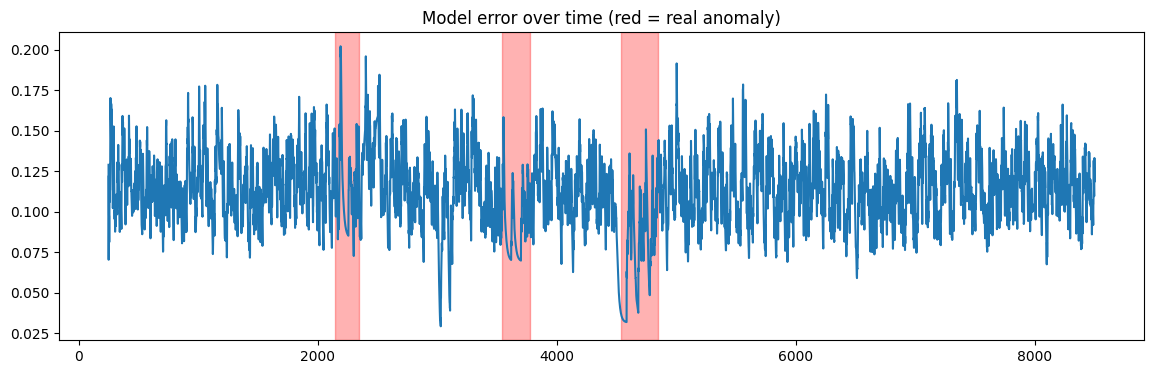

In [10]:
import pandas as pd

model.eval()
preds = []
with torch.no_grad():
    for i in range(0, len(X_test), 256):
        xb = torch.tensor(X_test[i:i + 256]).to(device)
        preds.append(model(xb).cpu().numpy())
y_pred = np.concatenate(preds)

errors = np.abs(y_test - y_pred)                         # gap between guess and reality
smooth = pd.Series(errors).ewm(span=30).mean().values    # calm down the noisy spikes

# windows start 250 steps in, so shift positions to match NASA's numbers
positions = np.arange(len(smooth)) + L

plt.figure(figsize=(14, 4))
plt.plot(positions, smooth)
for start, end in true_seqs:
    plt.axvspan(start, end, color="red", alpha=0.3)
plt.title("Model error over time (red = real anomaly)")
plt.show()

Threshold: 0.1925
Real anomalies: 3
Found: 1
False alarms: 1
Missed: 2


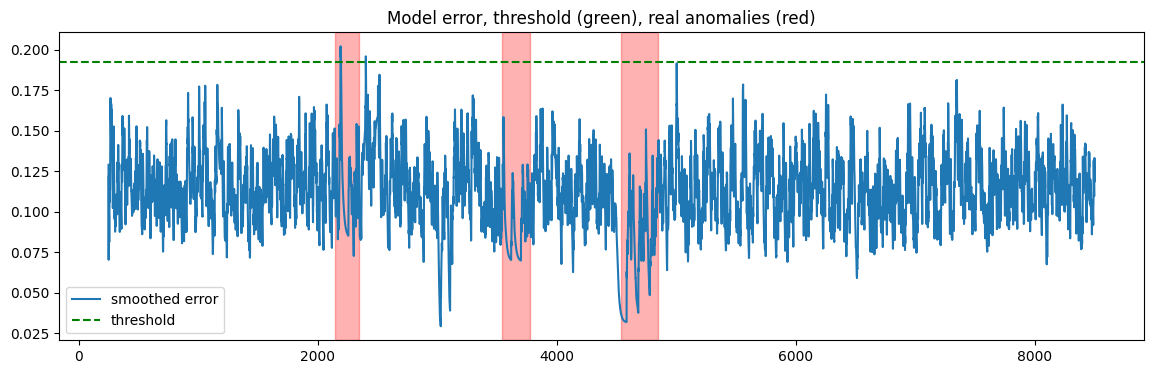

In [11]:
e = smooth

def dynamic_threshold(e, zs=np.arange(2.5, 10.5, 0.5)):
    best, best_score = e.mean() + zs[-1] * e.std(), -np.inf
    for z in zs:
        eps = e.mean() + z * e.std()
        below, above = e[e < eps], e > eps
        if not above.any():
            continue
        n_seq = np.sum(np.diff(above.astype(int)) == 1) + above[0]
        score = ((e.mean() - below.mean()) / e.mean() +
                 (e.std() - below.std()) / e.std()) / (above.sum() + n_seq ** 2)
        if score > best_score:
            best, best_score = eps, score
    return best

thr = dynamic_threshold(e)
flags = e > thr
pred_seqs = to_sequences(flags, ) if False else [[a + L, b + L] for a, b in to_sequences(flags)]

found, false_alarms, missed = score(pred_seqs, true_seqs)
print("Threshold:", round(thr, 4))
print("Real anomalies:", len(true_seqs))
print("Found:", found)
print("False alarms:", false_alarms)
print("Missed:", missed)

plt.figure(figsize=(14, 4))
plt.plot(positions, e, label="smoothed error")
plt.axhline(thr, color="green", linestyle="--", label="threshold")
for start, end in true_seqs:
    plt.axvspan(start, end, color="red", alpha=0.3)
plt.legend()
plt.title("Model error, threshold (green), real anomalies (red)")
plt.show()

In [17]:
def run_channel(chan, max_epochs=30, patience=5):
    torch.manual_seed(42)
    tr = np.load(BASE + f"data/data/train/{chan}.npy")
    te = np.load(BASE + f"data/data/test/{chan}.npy")
    row = labels[labels.chan_id == chan].iloc[0]
    true_seqs = ast.literal_eval(row.anomaly_sequences)

    Xa, ya = make_windows(tr)
    Xb, yb = make_windows(te)
    n_in = tr.shape[1]

    split = int(len(Xa) * 0.8)
    loader = DataLoader(TensorDataset(torch.tensor(Xa[:split]), torch.tensor(ya[:split])),
                        batch_size=64, shuffle=True)
    Xv = torch.tensor(Xa[split:]).to(device)
    yv = torch.tensor(ya[split:]).to(device)

    class ChanNet(nn.Module):
        def __init__(self):
            super().__init__()
            self.lstm = nn.LSTM(n_in, 80, num_layers=2, dropout=0.3, batch_first=True)
            self.out = nn.Linear(80, 1)
        def forward(self, x):
            o, _ = self.lstm(x)
            return self.out(o[:, -1, :]).squeeze(1)

    m = ChanNet().to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    best, state, bad = float("inf"), None, 0
    for ep in range(max_epochs):
        m.train()
        for xb, yb_ in loader:
            xb, yb_ = xb.to(device), yb_.to(device)
            opt.zero_grad()
            nn.functional.mse_loss(m(xb), yb_).backward()
            opt.step()
        m.eval()
        with torch.no_grad():
            v = nn.functional.mse_loss(m(Xv), yv).item()
        if v < best:
            best, bad = v, 0
            state = {k: t.clone() for k, t in m.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    m.load_state_dict(state)

    m.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(Xb), 256):
            preds.append(m(torch.tensor(Xb[i:i + 256]).to(device)).cpu().numpy())
    e = pd.Series(np.abs(yb - np.concatenate(preds))).ewm(span=30).mean().values

    thr = dynamic_threshold(e)
    pred_seqs = [[a + L, b + L] for a, b in to_sequences(e > thr)]
    found, fa, missed = score(pred_seqs, true_seqs)
    return dict(chan=chan, real=len(true_seqs), found=found, false_alarms=fa, missed=missed)

In [ ]:
results = []
for chan in ["P-1", "E-1", "A-1", "T-1", "D-1"]:
    found, fa, missed = run_channel(chan)
    r = dict(chan=chan, real=found + missed, found=found, false_alarms=fa, missed=missed)
    print(r)
    results.append(r)

pd.DataFrame(results)

In [ ]:
def run_baseline(chan):
    tr = np.load(BASE + f"data/data/train/{chan}.npy")
    te = np.load(BASE + f"data/data/test/{chan}.npy")
    row = labels[labels.chan_id == chan].iloc[0]
    true_seqs = ast.literal_eval(row.anomaly_sequences)

    z = np.abs(te[:, 0] - tr[:, 0].mean()) / tr[:, 0].std()
    pred_seqs = to_sequences(z > 3)
    found, fa, missed = score(pred_seqs, true_seqs)
    return dict(chan=chan, real=len(true_seqs), found=found, false_alarms=fa, missed=missed)

base_results = [run_baseline(c) for c in ["P-1", "E-1", "A-1", "T-1", "D-1"]]
base_df = pd.DataFrame(base_results)
print(base_df)
print("Totals:", base_df[["real", "found", "false_alarms", "missed"]].sum().to_dict())

In [ ]:
more = ["P-2", "E-2", "A-2", "T-2", "D-2", "M-1", "G-1", "F-1", "S-1", "C-1"]
for chan in more:
    r = run_channel(chan)
    print(r)
    results.append(r)

In [2]:
import os, ast
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

BASE = "/kaggle/input/datasets/patrickfleith/nasa-anomaly-detection-dataset-smap-msl/"
L = 250
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
labels = pd.read_csv(BASE + "labeled_anomalies.csv")
store = {}   # keeps errors/thresholds so we can plot later

def get_true_seqs(chan):
    seqs = []
    for s in labels[labels.chan_id == chan].anomaly_sequences:
        seqs += ast.literal_eval(s)
    return seqs

def make_windows(x):
    X = np.stack([x[i:i + L] for i in range(len(x) - L)])
    return X.astype("float32"), x[L:, 0].astype("float32")

def to_sequences(flags, offset=0):
    idx = np.flatnonzero(flags)
    if len(idx) == 0:
        return []
    parts = np.split(idx, np.flatnonzero(np.diff(idx) > 1) + 1)
    return [[p[0] + offset, p[-1] + offset] for p in parts]

def score(pred_seqs, true_seqs):
    hit = lambda a, b: a[0] <= b[1] and b[0] <= a[1]
    found = sum(any(hit(p, t) for p in pred_seqs) for t in true_seqs)
    fa = sum(not any(hit(p, t) for t in true_seqs) for p in pred_seqs)
    return found, fa, len(true_seqs) - found

def dynamic_threshold(e, zs=np.arange(2.5, 10.5, 0.5)):
    best, best_score = e.mean() + zs[-1] * e.std(), -np.inf
    for z in zs:
        eps = e.mean() + z * e.std()
        below, above = e[e < eps], e > eps
        if not above.any():
            continue
        n_seq = np.sum(np.diff(above.astype(int)) == 1) + above[0]
        sc = ((e.mean() - below.mean()) / e.mean() +
              (e.std() - below.std()) / e.std()) / (above.sum() + n_seq ** 2)
        if sc > best_score:
            best, best_score = eps, sc
    return best

def run_baseline(chan):
    tr = np.load(BASE + f"data/data/train/{chan}.npy")
    te = np.load(BASE + f"data/data/test/{chan}.npy")
    z = np.abs(te[:, 0] - tr[:, 0].mean()) / (tr[:, 0].std() + 1e-9)
    return score(to_sequences(z > 3), get_true_seqs(chan))

def run_channel(chan, max_epochs=30, patience=5):
    torch.manual_seed(42)
    tr = np.load(BASE + f"data/data/train/{chan}.npy")
    te = np.load(BASE + f"data/data/test/{chan}.npy")
    true_seqs = get_true_seqs(chan)
    Xa, ya = make_windows(tr)
    Xb, yb = make_windows(te)
    n_in = tr.shape[1]

    split = int(len(Xa) * 0.8)
    loader = DataLoader(TensorDataset(torch.tensor(Xa[:split]), torch.tensor(ya[:split])),
                        batch_size=64, shuffle=True)
    Xv = torch.tensor(Xa[split:]).to(device)
    yv = torch.tensor(ya[split:]).to(device)

    class ChanNet(nn.Module):
        def __init__(self):
            super().__init__()
            self.lstm = nn.LSTM(n_in, 80, num_layers=2, dropout=0.3, batch_first=True)
            self.out = nn.Linear(80, 1)
        def forward(self, x):
            o, _ = self.lstm(x)
            return self.out(o[:, -1, :]).squeeze(1)

    m = ChanNet().to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    best, state, bad = float("inf"), None, 0
    for ep in range(max_epochs):
        m.train()
        for xb, yb_ in loader:
            xb, yb_ = xb.to(device), yb_.to(device)
            opt.zero_grad()
            nn.functional.mse_loss(m(xb), yb_).backward()
            opt.step()
        m.eval()
        with torch.no_grad():
            v = nn.functional.mse_loss(m(Xv), yv).item()
        if v < best:
            best, bad = v, 0
            state = {k: t.clone() for k, t in m.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    m.load_state_dict(state)

    m.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(Xb), 256):
            preds.append(m(torch.tensor(Xb[i:i + 256]).to(device)).cpu().numpy())
    e = pd.Series(np.abs(yb - np.concatenate(preds))).ewm(span=30).mean().values
    thr = dynamic_threshold(e)
    pred_seqs = to_sequences(e > thr, offset=L)
    store[chan] = dict(signal=te[:, 0], e=e, thr=thr, true=true_seqs)
    return score(pred_seqs, true_seqs)

device: cpu


In [1]:
smap = list(labels[labels.spacecraft == "SMAP"].chan_id.unique()[:12])
msl  = list(labels[labels.spacecraft == "MSL"].chan_id.unique()[:8])

CHANNELS = smap + msl

RESULTS_FILE = "/kaggle/working/results.csv"

rows = (
    pd.read_csv(RESULTS_FILE).to_dict("records")
    if os.path.exists(RESULTS_FILE)
    else []
)

done = {r["chan"] for r in rows}

for chan in CHANNELS:

    if chan in done:
        print("Skipping already completed:", chan)
        continue

    print("\nStarting:", chan)

    # Run the simple baseline
    bf, bfa, bm = run_baseline(chan)

    # Train and evaluate the LSTM
    f, fa, m_ = run_channel(chan)

    # Identify spacecraft
    sc = labels[labels.chan_id == chan].spacecraft.iloc[0]

    # Save results
    rows.append(dict(
        chan=chan,
        spacecraft=sc,
        real=f + m_,
        base_found=bf,
        base_fa=bfa,
        lstm_found=f,
        lstm_fa=fa
    ))

    pd.DataFrame(rows).to_csv(RESULTS_FILE, index=False)

    print(
        chan, sc,
        "| Real anomalies:", f + m_,
        "| Baseline:", bf, "found,", bfa, "false alarms",
        "| LSTM:", f, "found,", fa, "false alarms"
    )

print("\nAll completed channels have been processed!")
print("Results saved to:", RESULTS_FILE)

NameError: name 'labels' is not defined

In [2]:
labels = pd.read_csv(BASE + "labeled_anomalies.csv")

NameError: name 'pd' is not defined

In [3]:
import os
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

print("All libraries loaded successfully!")

All libraries loaded successfully!


In [4]:
BASE = "/kaggle/input/datasets/patrickfleith/nasa-anomaly-detection-dataset-smap-msl/"

L = 250

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

labels = pd.read_csv(BASE + "labeled_anomalies.csv")

store = {}

def get_true_seqs(chan):
    seqs = []
    for s in labels[labels.chan_id == chan].anomaly_sequences:
        seqs += ast.literal_eval(s)
    return seqs

def make_windows(x):
    X = np.stack([x[i:i + L] for i in range(len(x) - L)])
    return X.astype("float32"), x[L:, 0].astype("float32")

def to_sequences(flags, offset=0):
    idx = np.flatnonzero(flags)
    if len(idx) == 0:
        return []
    parts = np.split(idx, np.flatnonzero(np.diff(idx) > 1) + 1)
    return [[p[0] + offset, p[-1] + offset] for p in parts]

def score(pred_seqs, true_seqs):
    hit = lambda a, b: a[0] <= b[1] and b[0] <= a[1]
    found = sum(any(hit(p, t) for p in pred_seqs) for t in true_seqs)
    fa = sum(not any(hit(p, t) for t in true_seqs) for p in pred_seqs)
    return found, fa, len(true_seqs) - found

def dynamic_threshold(e, zs=np.arange(2.5, 10.5, 0.5)):
    best, best_score = e.mean() + zs[-1] * e.std(), -np.inf
    for z in zs:
        eps = e.mean() + z * e.std()
        below, above = e[e < eps], e > eps
        if not above.any():
            continue
        n_seq = np.sum(np.diff(above.astype(int)) == 1) + above[0]
        sc = ((e.mean() - below.mean()) / e.mean() +
              (e.std() - below.std()) / e.std()) / (above.sum() + n_seq ** 2)
        if sc > best_score:
            best, best_score = eps, sc
    return best

def run_baseline(chan):
    tr = np.load(BASE + f"data/data/train/{chan}.npy")
    te = np.load(BASE + f"data/data/test/{chan}.npy")
    z = np.abs(te[:, 0] - tr[:, 0].mean()) / (tr[:, 0].std() + 1e-9)
    return score(to_sequences(z > 3), get_true_seqs(chan))

def run_channel(chan, max_epochs=30, patience=5):
    torch.manual_seed(42)

    tr = np.load(BASE + f"data/data/train/{chan}.npy")
    te = np.load(BASE + f"data/data/test/{chan}.npy")
    true_seqs = get_true_seqs(chan)

    Xa, ya = make_windows(tr)
    Xb, yb = make_windows(te)
    n_in = tr.shape[1]

    split = int(len(Xa) * 0.8)

    loader = DataLoader(
        TensorDataset(torch.tensor(Xa[:split]), torch.tensor(ya[:split])),
        batch_size=64,
        shuffle=True
    )

    Xv = torch.tensor(Xa[split:]).to(device)
    yv = torch.tensor(ya[split:]).to(device)

    class ChanNet(nn.Module):
        def __init__(self):
            super().__init__()
            self.lstm = nn.LSTM(
                n_in, 80, num_layers=2,
                dropout=0.3, batch_first=True
            )
            self.out = nn.Linear(80, 1)

        def forward(self, x):
            o, _ = self.lstm(x)
            return self.out(o[:, -1, :]).squeeze(1)

    m = ChanNet().to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)

    best, state, bad = float("inf"), None, 0

    for ep in range(max_epochs):
        m.train()

        for xb, yb_ in loader:
            xb, yb_ = xb.to(device), yb_.to(device)
            opt.zero_grad()
            nn.functional.mse_loss(m(xb), yb_).backward()
            opt.step()

        m.eval()

        with torch.no_grad():
            v = nn.functional.mse_loss(m(Xv), yv).item()

        if v < best:
            best, bad = v, 0
            state = {k: t.clone() for k, t in m.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break

    m.load_state_dict(state)
    m.eval()

    preds = []

    with torch.no_grad():
        for i in range(0, len(Xb), 256):
            preds.append(
                m(torch.tensor(Xb[i:i + 256]).to(device)).cpu().numpy()
            )

    e = pd.Series(
        np.abs(yb - np.concatenate(preds))
    ).ewm(span=30).mean().values

    thr = dynamic_threshold(e)
    pred_seqs = to_sequences(e > thr, offset=L)

    store[chan] = dict(
        signal=te[:, 0], e=e, thr=thr, true=true_seqs
    )

    return score(pred_seqs, true_seqs)

print("Cell 1 completed successfully!")

device: cpu
Cell 1 completed successfully!


In [5]:
smap = list(labels[labels.spacecraft == "SMAP"].chan_id.unique()[:12])
msl = list(labels[labels.spacecraft == "MSL"].chan_id.unique()[:8])

CHANNELS = smap + msl

RESULTS_FILE = "/kaggle/working/results.csv"

rows = (
    pd.read_csv(RESULTS_FILE).to_dict("records")
    if os.path.exists(RESULTS_FILE)
    else []
)

done = {r["chan"] for r in rows}

for chan in CHANNELS:

    if chan in done:
        print("Skipping:", chan)
        continue

    print("\nStarting:", chan)

    bf, bfa, bm = run_baseline(chan)
    f, fa, m_ = run_channel(chan)

    sc = labels[labels.chan_id == chan].spacecraft.iloc[0]

    rows.append(dict(
        chan=chan,
        spacecraft=sc,
        real=f + m_,
        base_found=bf,
        base_fa=bfa,
        lstm_found=f,
        lstm_fa=fa
    ))

    pd.DataFrame(rows).to_csv(RESULTS_FILE, index=False)

    print(
        chan, sc,
        "| Real:", f + m_,
        "| Baseline:", bf, "found,", bfa, "false alarms",
        "| LSTM:", f, "found,", fa, "false alarms"
    )

print("\nALL CHANNELS COMPLETED!")


Starting: P-1
P-1 SMAP | Real: 3 | Baseline: 2 found, 37 false alarms | LSTM: 1 found, 1 false alarms

Starting: S-1
S-1 SMAP | Real: 1 | Baseline: 0 found, 0 false alarms | LSTM: 1 found, 0 false alarms

Starting: E-1
E-1 SMAP | Real: 2 | Baseline: 0 found, 0 false alarms | LSTM: 1 found, 2 false alarms

Starting: E-2
E-2 SMAP | Real: 1 | Baseline: 0 found, 0 false alarms | LSTM: 1 found, 0 false alarms

Starting: E-3
E-3 SMAP | Real: 1 | Baseline: 0 found, 0 false alarms | LSTM: 1 found, 0 false alarms

Starting: E-4
E-4 SMAP | Real: 1 | Baseline: 0 found, 1 false alarms | LSTM: 1 found, 1 false alarms

Starting: E-5
E-5 SMAP | Real: 1 | Baseline: 0 found, 0 false alarms | LSTM: 0 found, 1 false alarms

Starting: E-6
E-6 SMAP | Real: 1 | Baseline: 1 found, 0 false alarms | LSTM: 1 found, 0 false alarms

Starting: E-7


KeyboardInterrupt: 

In [6]:
df = pd.read_csv("/kaggle/working/results.csv")
print(len(df), "channels saved")
df

8 channels saved


,chan,spacecraft,real,base_found,base_fa,lstm_found,lstm_fa
0,P-1,SMAP,3,2,37,1,1
1,S-1,SMAP,1,0,0,1,0
2,E-1,SMAP,2,0,0,1,2
3,E-2,SMAP,1,0,0,1,0
4,E-3,SMAP,1,0,0,1,0
5,E-4,SMAP,1,0,1,1,1
6,E-5,SMAP,1,0,0,0,1
7,E-6,SMAP,1,1,0,1,0


In [7]:
df = pd.read_csv("/kaggle/working/results.csv")

def summarize(d):
    R = d.real.sum()
    out = {}
    for name, f, fa in [("baseline", d.base_found.sum(), d.base_fa.sum()),
                        ("LSTM", d.lstm_found.sum(), d.lstm_fa.sum())]:
        out[name] = dict(found=f, false_alarms=fa, real=R,
                         precision=round(f / max(f + fa, 1), 3),
                         recall=round(f / R, 3))
    return pd.DataFrame(out).T

print("ALL CHANNELS"); print(summarize(df))
for sc in ["SMAP", "MSL"]:
    part = df[df.spacecraft == sc]
    if len(part):
        print("\n", sc); print(summarize(part))

ALL CHANNELS
          found  false_alarms  real  precision  recall
baseline    3.0          38.0  11.0      0.073   0.273
LSTM        7.0           5.0  11.0      0.583   0.636

 SMAP
          found  false_alarms  real  precision  recall
baseline    3.0          38.0  11.0      0.073   0.273
LSTM        7.0           5.0  11.0      0.583   0.636


In [8]:
print(open("/kaggle/working/results.csv").read())

chan,spacecraft,real,base_found,base_fa,lstm_found,lstm_fa
P-1,SMAP,3,2,37,1,1
S-1,SMAP,1,0,0,1,0
E-1,SMAP,2,0,0,1,2
E-2,SMAP,1,0,0,1,0
E-3,SMAP,1,0,0,1,0
E-4,SMAP,1,0,1,1,1
E-5,SMAP,1,0,0,0,1
E-6,SMAP,1,1,0,1,0



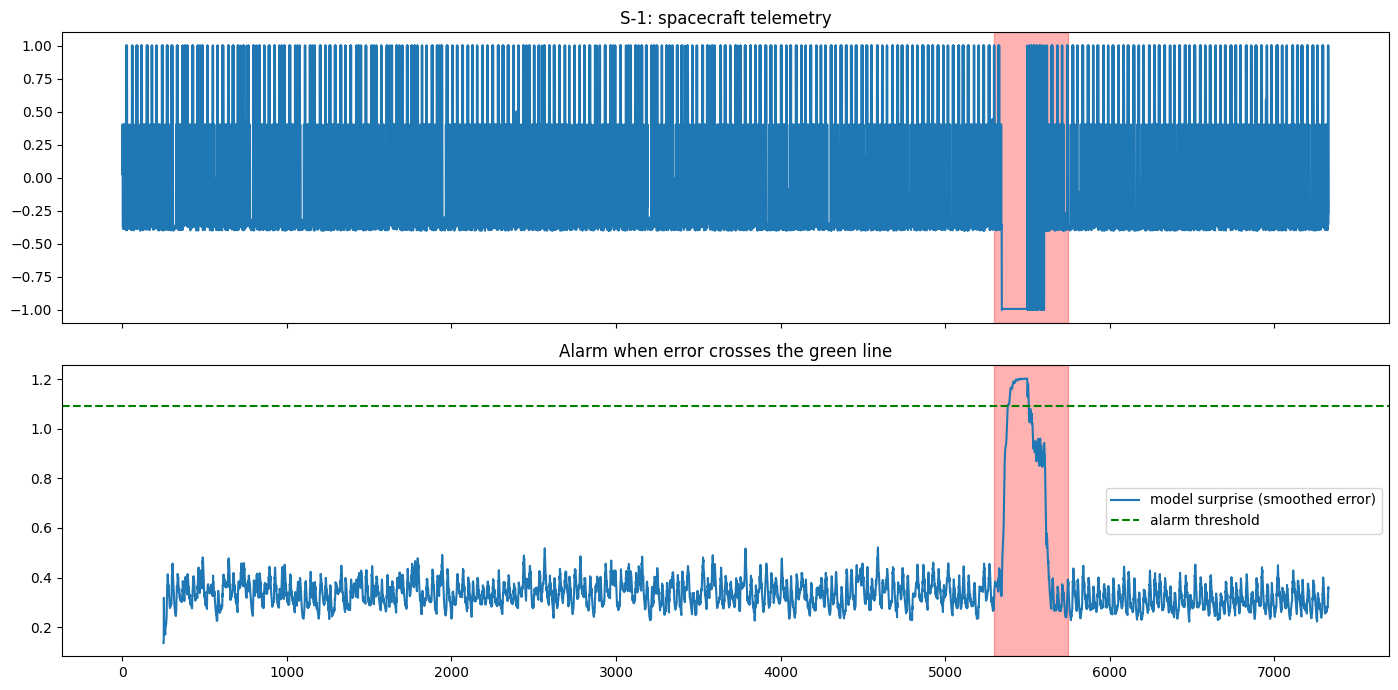


Tested on 8 channels (11 expert-labeled anomalies).
Baseline (z-score): precision 0.073, recall 0.273
LSTM:               precision 0.583, recall 0.636



In [9]:
df = pd.read_csv("/kaggle/working/results.csv")

def summarize(d):
    R = d.real.sum()
    out = {}
    for name, f, fa in [("baseline", d.base_found.sum(), d.base_fa.sum()),
                        ("LSTM", d.lstm_found.sum(), d.lstm_fa.sum())]:
        out[name] = dict(found=f, false_alarms=fa, real=R,
                         precision=round(f / max(f + fa, 1), 3),
                         recall=round(f / R, 3))
    return pd.DataFrame(out).T

good = df[(df.lstm_found == df.real) & (df.lstm_fa == 0) & (df.chan.isin(store))]
chan = good.chan.iloc[0] if len(good) else list(store)[0]
s = store[chan]

fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
ax[0].plot(s["signal"]); ax[0].set_title(f"{chan}: spacecraft telemetry")
ax[1].plot(np.arange(len(s["e"])) + L, s["e"], label="model surprise (smoothed error)")
ax[1].axhline(s["thr"], color="green", ls="--", label="alarm threshold")
ax[1].legend(); ax[1].set_title("Alarm when error crosses the green line")
for a in ax:
    for st, en in s["true"]:
        a.axvspan(st, en, color="red", alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/showcase.png", dpi=150)
plt.show()

t = summarize(df)
print(f"""
Tested on {len(df)} channels ({df.real.sum()} expert-labeled anomalies).
Baseline (z-score): precision {t.loc['baseline','precision']}, recall {t.loc['baseline','recall']}
LSTM:               precision {t.loc['LSTM','precision']}, recall {t.loc['LSTM','recall']}
""")

In [10]:
import pandas as pd
import os

RESULTS_FILE = "/kaggle/working/results.csv"

if os.path.exists(RESULTS_FILE):
    df = pd.read_csv(RESULTS_FILE)

    print("CHANNELS COMPLETED:", len(df))
    print("\nYOUR RESULTS:")
    print(df.to_string(index=False))

    print("\nRESULTS FILE EXISTS:", os.path.exists(RESULTS_FILE))
else:
    print("results.csv not found!")

CHANNELS COMPLETED: 8

YOUR RESULTS:
chan spacecraft  real  base_found  base_fa  lstm_found  lstm_fa
 P-1       SMAP     3           2       37           1        1
 S-1       SMAP     1           0        0           1        0
 E-1       SMAP     2           0        0           1        2
 E-2       SMAP     1           0        0           1        0
 E-3       SMAP     1           0        0           1        0
 E-4       SMAP     1           0        1           1        1
 E-5       SMAP     1           0        0           0        1
 E-6       SMAP     1           1        0           1        0

RESULTS FILE EXISTS: True


In [11]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/results.csv"))

/kaggle/working/results.csv

In [12]:
import os

for filename in ["results.csv", "showcase.png"]:
    path = "/kaggle/working/" + filename
    print(filename, "→", "EXISTS" if os.path.exists(path) else "NOT FOUND")

results.csv → EXISTS
showcase.png → EXISTS
